# SmolVLA Fine-Tuning on Berkeley UR5 Dataset

This notebook walks through the complete pipeline of fine-tuning HuggingFace's **SmolVLA** Vision-Language-Action model on the **Berkeley AutoLab UR5** dataset using the **LeRobot** framework.

**What you'll do:**
1. Install dependencies
2. Load and explore the Berkeley UR5 dataset
3. Visualize sample trajectories
4. Configure and launch SmolVLA fine-tuning
5. Monitor training
6. Evaluate the trained policy
7. Export the model for deployment

---
## 1. Environment Setup

In [1]:
# Install LeRobot with SmolVLA support
# Run this once, then restart the kernel
!pip install -q "lerobot[smolvla]" wandb matplotlib

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
import os

# Check GPU availability
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:             {torch.cuda.get_device_name(0)}")
    # Change total_mem to total_memory here:
    print(f"VRAM:            {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


PyTorch version: 2.7.1+cu126
CUDA available:  True
GPU:             NVIDIA GeForce RTX 2080 Ti
VRAM:            11.3 GB


In [5]:
# (Optional) Login to HuggingFace Hub
from huggingface_hub import login
login()  # Paste your token when prompted

---
## 2. Load & Explore the Berkeley UR5 Dataset

In [7]:
!cd lerobot/ && pip install -e .

Obtaining file:///home/grasplab/Desktop/VLA/berk/lerobot
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for lerobot (pyproject.toml) ... done
  Created wheel for lerobot: filename=lerobot-0.4.4-0.editable-py3-none-any.whl size=12600 sha256=917677e5cd8d3f5081e28fa7a805bf12478a20e0d5c3647110a01e3aaa35b421
  Stored in directory: /tmp/pip-ephem-wheel-cache-o7qk1v2_/wheels/a0/7a/73/4081acb03102d4f44a3ca9fb331705837c770b15264db07ee8
Successfully built lerobot
  Attempting uninstall: lerobot
    Found existing installation: lerobot 0.4.4
    Uninstalling lerobot-0.4.4:
      Successfully uninstalled lerobot-0.4.4


In [13]:
!cd lerobot/ && pip install ".[all]"

Processing /home/grasplab/Desktop/VLA/berk/lerobot
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached gym_aloha-0.1.3-py3-none-any.whl.metadata (7.2 kB)
  Using cached dm_control-1.0.38-py3-none-any.whl.metadata (1.5 kB)
  Using cached mujoco-3.6.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (42 kB)
  Using cached absl_py-2.4.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached dm_env-1.6-py3-none-any.whl.metadata (966 bytes)
  Using cached dm_tree-0.1.10-cp310-cp310-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (2.6 kB)
  Using cached glfw-2.10.0-py2.py27.py3.py30.py31.py32.py33.py34.py35.py36.py37.py38.py39.py310.py311.py312.py313.py314-none-manylinux_2_28_x86_64.whl.metadata (5.4 kB)
  Using cached labmaze-1.0.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (278 bytes)
  Using cached lxml-6.0.3-cp310-cp310-manylinux_2_26_x86_64.m

In [7]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

# Load the dataset (downloads from HuggingFace Hub on first run)
DATASET_REPO_ID = "lerobot/berkeley_autolab_ur5"
dataset = LeRobotDataset(DATASET_REPO_ID)

print("=" * 60)
print("BERKELEY UR5 DATASET INFO")
print("=" * 60)
print(f"Total episodes:  {dataset.meta.total_episodes}")
print(f"Total frames:    {dataset.meta.total_frames}")
print(f"FPS:             {dataset.meta.fps}")
print(f"Robot type:      {dataset.meta.robot_type}")
print(f"Video keys:      {dataset.meta.video_keys}")
print(f"Total tasks:     {dataset.meta.total_tasks}")

BERKELEY UR5 DATASET INFO
Total episodes:  1000
Total frames:    97939
FPS:             5
Robot type:      unknown
Video keys:      ['observation.images.image_with_depth', 'observation.images.image', 'observation.images.hand_image']
Total tasks:     5


In [10]:
import torch
# Inspect a single sample
sample = dataset[0]
print("\nSample keys and shapes:")
print("-" * 60)
for key, value in sample.items():
    if isinstance(value, torch.Tensor):
        print(f"  {key:45s} | {str(value.shape):20s} | {value.dtype}")
    elif isinstance(value, str):
        print(f"  {key:45s} | str: '{value[:60]}...'" if len(str(value)) > 60 else f"  {key:45s} | str: '{value}'")
    else:
        print(f"  {key:45s} | {type(value).__name__}: {value}")


Sample keys and shapes:
------------------------------------------------------------
  observation.images.image_with_depth           | torch.Size([3, 480, 640]) | torch.float32
  observation.images.image                      | torch.Size([3, 480, 640]) | torch.float32
  observation.images.hand_image                 | torch.Size([3, 480, 640]) | torch.float32
  observation.state                             | torch.Size([8])      | torch.float32
  action                                        | torch.Size([7])      | torch.float32
  timestamp                                     | torch.Size([])       | torch.float32
  episode_index                                 | torch.Size([])       | torch.int64
  frame_index                                   | torch.Size([])       | torch.int64
  next.reward                                   | torch.Size([])       | torch.float32
  next.done                                     | torch.Size([])       | torch.bool
  index                             

---
## 3. Visualize Sample Trajectories

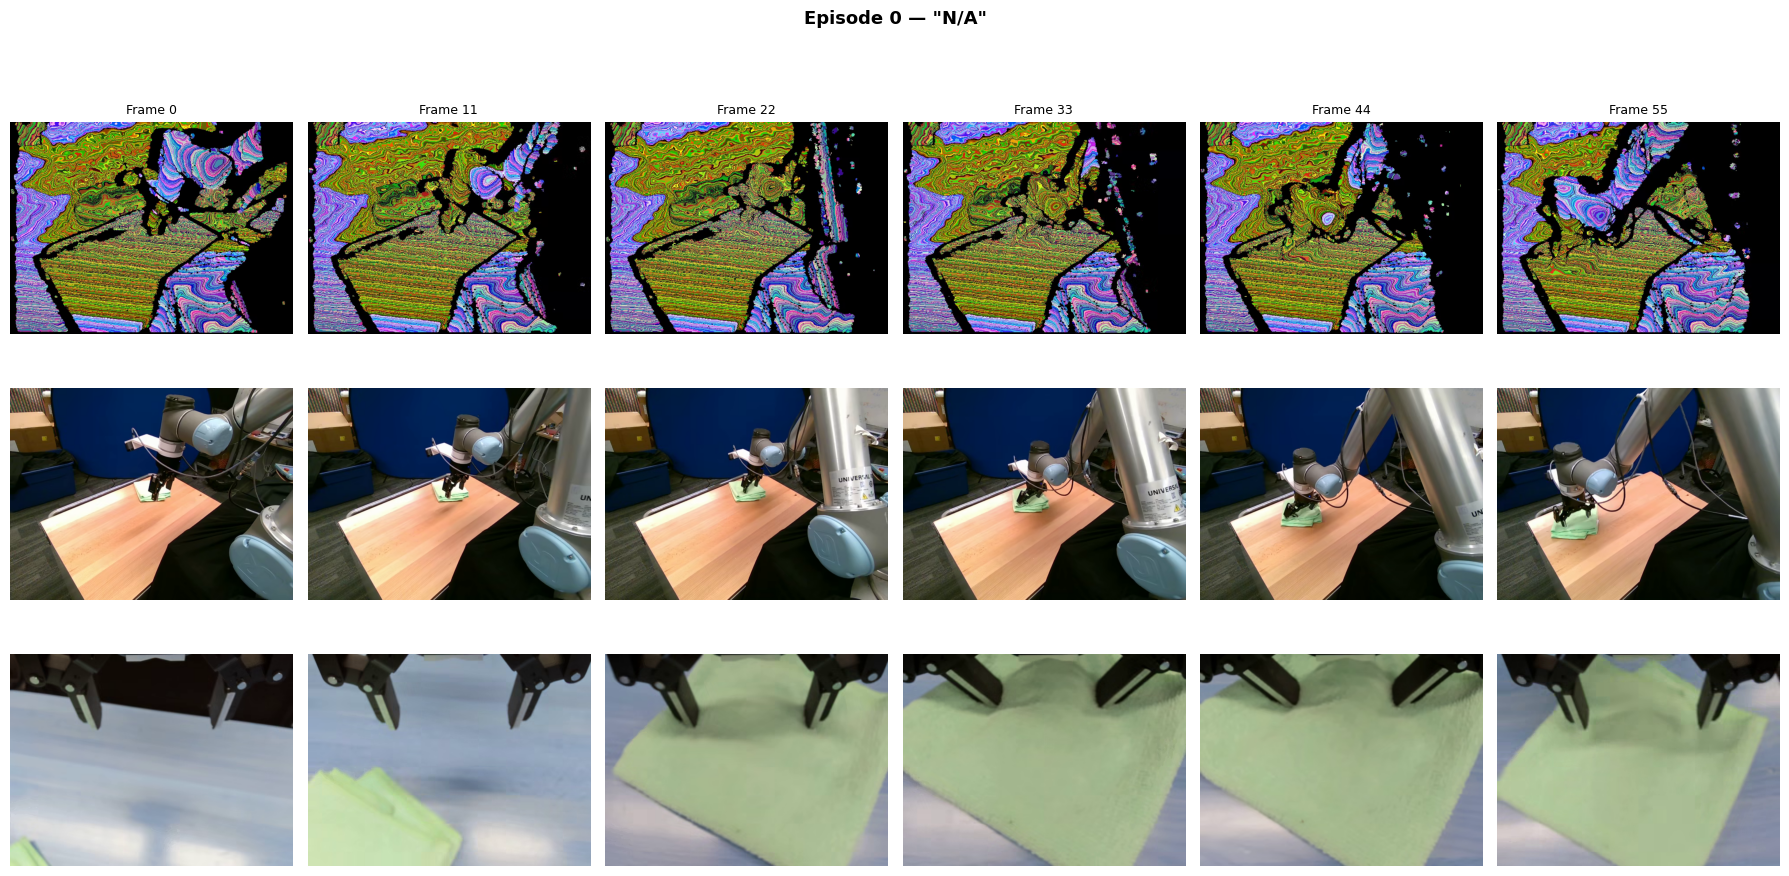

In [13]:
def visualize_episode(dataset, episode_idx=0, num_frames=8):
    """
    Visualize frames from a single episode showing all camera views.
    """
    # Get indices for this episode
    ep_start = None
    ep_end = None
    for i in range(len(dataset)):
        sample = dataset[i]
        if sample.get('episode_index', sample.get('episode_index', -1)) == episode_idx:
            if ep_start is None:
                ep_start = i
            ep_end = i
        elif ep_start is not None:
            break
    
    if ep_start is None:
        print(f"Episode {episode_idx} not found")
        return
    
    ep_length = ep_end - ep_start + 1
    step = max(1, ep_length // num_frames)
    frame_indices = range(ep_start, ep_end + 1, step)[:num_frames]
    
    # Determine available camera keys
    camera_keys = [k for k in dataset[ep_start].keys() if 'image' in k and isinstance(dataset[ep_start][k], torch.Tensor)]
    
    fig, axes = plt.subplots(len(camera_keys), num_frames, 
                              figsize=(3 * num_frames, 3 * len(camera_keys)))
    if len(camera_keys) == 1:
        axes = axes.reshape(1, -1)
    
    for col, idx in enumerate(frame_indices):
        sample = dataset[idx]
        for row, cam_key in enumerate(camera_keys):
            img = sample[cam_key]
            if img.dim() == 3 and img.shape[0] in [1, 3]:
                img = img.permute(1, 2, 0)
            img_np = img.numpy()
            if img_np.max() <= 1.0:
                img_np = (img_np * 255).astype(np.uint8)
            axes[row, col].imshow(img_np)
            axes[row, col].axis('off')
            if col == 0:
                short_name = cam_key.split('.')[-1]
                axes[row, col].set_ylabel(short_name, fontsize=10, rotation=0, labelpad=80)
            if row == 0:
                axes[row, col].set_title(f'Frame {idx - ep_start}', fontsize=9)
    
    # Get task instruction
    task = dataset[ep_start].get('language_instruction', 'N/A')
    fig.suptitle(f'Episode {episode_idx} — "{task}"', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Visualize the first episode
visualize_episode(dataset, episode_idx=0, num_frames=6)

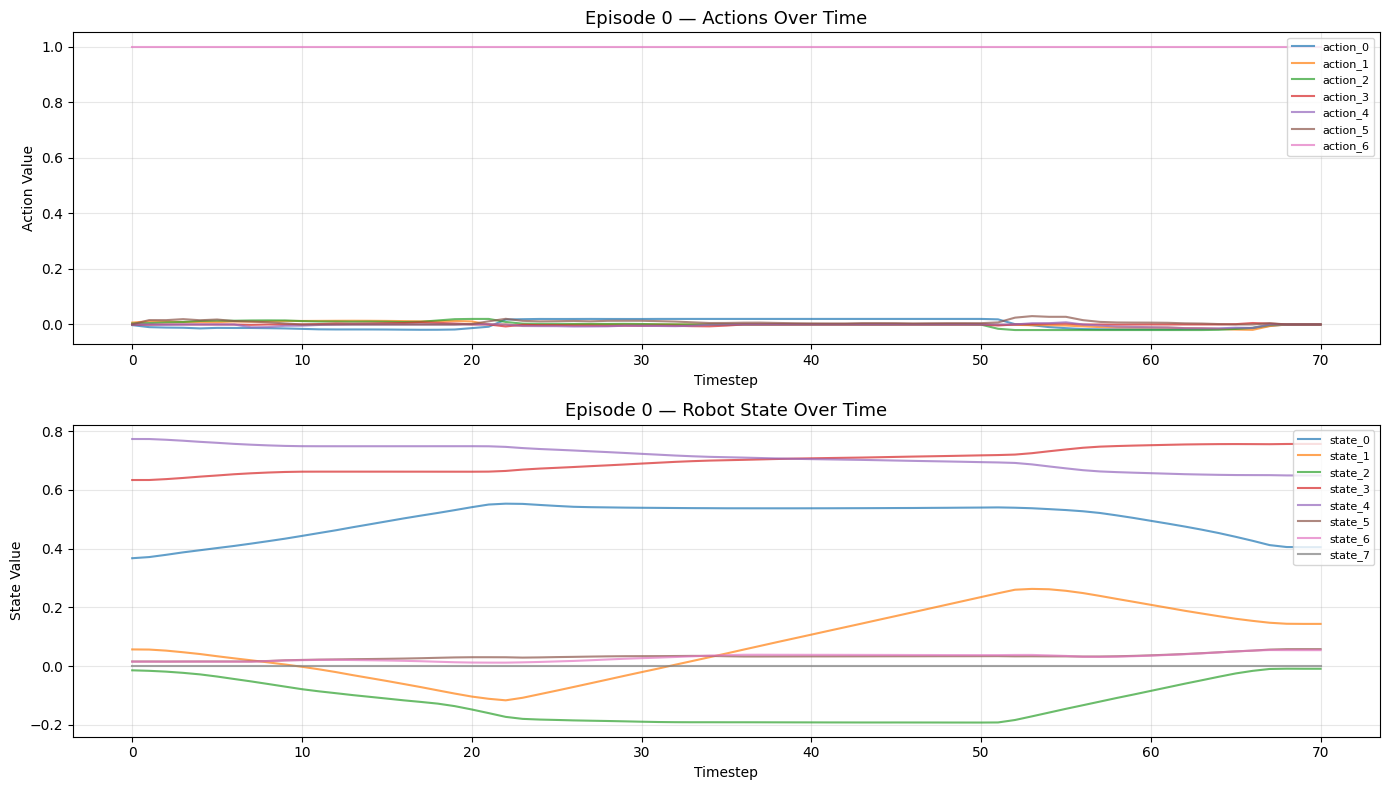

Action dimension: 7
Action range: [-0.0200, 1.0000]


In [14]:
def plot_episode_actions(dataset, episode_idx=0):
    """
    Plot the action trajectory for a given episode.
    """
    actions = []
    states = []
    found = False
    
    for i in range(len(dataset)):
        sample = dataset[i]
        ep_idx = sample.get('episode_index', -1)
        if isinstance(ep_idx, torch.Tensor):
            ep_idx = ep_idx.item()
        if ep_idx == episode_idx:
            found = True
            actions.append(sample['action'].numpy())
            if 'observation.state' in sample:
                states.append(sample['observation.state'].numpy())
        elif found:
            break
    
    actions = np.array(actions)
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    # Plot actions
    action_labels = [f'action_{i}' for i in range(actions.shape[1])]
    for i in range(actions.shape[1]):
        axes[0].plot(actions[:, i], label=action_labels[i], alpha=0.7)
    axes[0].set_title(f'Episode {episode_idx} — Actions Over Time', fontsize=13)
    axes[0].set_xlabel('Timestep')
    axes[0].set_ylabel('Action Value')
    axes[0].legend(loc='upper right', fontsize=8)
    axes[0].grid(True, alpha=0.3)
    
    # Plot states
    if states:
        states = np.array(states)
        for i in range(min(states.shape[1], 8)):
            axes[1].plot(states[:, i], label=f'state_{i}', alpha=0.7)
        axes[1].set_title(f'Episode {episode_idx} — Robot State Over Time', fontsize=13)
        axes[1].set_xlabel('Timestep')
        axes[1].set_ylabel('State Value')
        axes[1].legend(loc='upper right', fontsize=8)
        axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    print(f"Action dimension: {actions.shape[1]}")
    print(f"Action range: [{actions.min():.4f}, {actions.max():.4f}]")

plot_episode_actions(dataset, episode_idx=0)

---
## 4. Configure Training

We'll fine-tune SmolVLA using the LeRobot training infrastructure. Key hyperparameters are explained below.

In [32]:
# ──── Training Configuration ────

TRAIN_CONFIG = {
    # Model
    "policy_type": "smolvla",
    "pretrained_path": "lerobot/smolvla_base",  # base pre-trained model
    
    # Dataset
    "dataset_repo_id": "lerobot/berkeley_autolab_ur5",
    
    # Training hyperparameters
    "batch_size": 8,        # Reduce to 8 or 16 if OOM
    "learning_rate": 1e-4,   # Conservative for fine-tuning
    "training_steps": 20000, # ~205 epochs over 1000 episodes
    "num_workers": 4,        # Data loading workers
    
    # Output
    "output_dir": "outputs/train/smolvla_berkeley_ur5",
    "job_name": "smolvla_berkeley_ur5",
    
    # Logging
    "wandb_enable": False,   # Set True if you have W&B configured
    
    # Hardware
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

print("Training Configuration:")
print("=" * 50)
for k, v in TRAIN_CONFIG.items():
    print(f"  {k:25s}: {v}")

Training Configuration:
  policy_type              : smolvla
  pretrained_path          : lerobot/smolvla_base
  dataset_repo_id          : lerobot/berkeley_autolab_ur5
  batch_size               : 8
  learning_rate            : 0.0001
  training_steps           : 20000
  num_workers              : 4
  output_dir               : outputs/train/smolvla_berkeley_ur5
  job_name                 : smolvla_berkeley_ur5
  wandb_enable             : False
  device                   : cuda


### 4.1 Understanding the Hyperparameters

| Parameter | Value | Rationale |
|---|---|---|
| `batch_size` | 32 | Good balance of gradient stability and VRAM usage |
| `learning_rate` | 1e-4 | Standard for VLA fine-tuning; prevents catastrophic forgetting |
| `training_steps` | 20,000 | ~200 passes over 97.9K frames with batch 32 |
| `pretrained_path` | smolvla_base | Uses HF pre-trained weights as initialization |

---
## 5. Launch Training

We run training via the LeRobot CLI. This cell builds the command and executes it.

In [33]:
# Build the training command
train_cmd = f"""
lerobot-train \
    --policy.type=smolvla \
    --policy.pretrained_path={TRAIN_CONFIG['pretrained_path']} \
    --policy.push_to_hub=false \
    --dataset.repo_id={TRAIN_CONFIG['dataset_repo_id']} \
    --dataset.video_backend=pyav \
    --optimizer.lr={TRAIN_CONFIG['learning_rate']} \
    --steps={TRAIN_CONFIG['training_steps']} \
    --output_dir={TRAIN_CONFIG['output_dir']} \
    --job_name={TRAIN_CONFIG['job_name']} \
    --num_workers={TRAIN_CONFIG['num_workers']} \
    --wandb.enable={str(TRAIN_CONFIG['wandb_enable']).lower()} \
    --batch_size={TRAIN_CONFIG['batch_size']} \
    --tolerance_s=1.0
""".strip()





print("Training command:")
print("=" * 70)
print(train_cmd)
print("\n" + "=" * 70)
print("\n⚠️  Run the cell below to start training.")
print("    Expected time: 2-6 hours on an RTX 4090 / A100.")
print("    Reduce batch_size if you encounter CUDA OOM errors.")

Training command:
lerobot-train     --policy.type=smolvla     --policy.pretrained_path=lerobot/smolvla_base     --policy.push_to_hub=false     --dataset.repo_id=lerobot/berkeley_autolab_ur5     --dataset.video_backend=pyav     --optimizer.lr=0.0001     --steps=20000     --output_dir=outputs/train/smolvla_berkeley_ur5     --job_name=smolvla_berkeley_ur5     --num_workers=4     --wandb.enable=false     --batch_size=8     --tolerance_s=1.0


⚠️  Run the cell below to start training.
    Expected time: 2-6 hours on an RTX 4090 / A100.
    Reduce batch_size if you encounter CUDA OOM errors.


In [34]:
# ╔═══════════════════════════════════════════════╗
# ║  🚀 START TRAINING — Execute this cell         ║
# ╚═══════════════════════════════════════════════╝

!{train_cmd}

INFO 2026-04-11 03:26:45 ot_train.py:195 {'batch_size': 8,
 'checkpoint_path': None,
 'dataset': {'episodes': None,
             'image_transforms': {'enable': False,
                                  'max_num_transforms': 3,
                                  'random_order': False,
                                  'tfs': {'affine': {'kwargs': {'degrees': [-5.0,
                                                                            5.0],
                                                                'translate': [0.05,
                                                                              0.05]},
                                                     'type': 'RandomAffine',
                                                     'weight': 1.0},
                                          'brightness': {'kwargs': {'brightness': [0.8,
                                                                                   1.2]},
                                                         't

---
## 6. Monitor & Analyze Training

After training completes (or while it runs), you can analyze the results.

In [35]:
# Check what was saved
output_dir = Path(TRAIN_CONFIG['output_dir'])

if output_dir.exists():
    print("Output directory contents:")
    for item in sorted(output_dir.rglob('*')):
        if item.is_file():
            size_mb = item.stat().st_size / 1e6
            rel = item.relative_to(output_dir)
            print(f"  {str(rel):50s} ({size_mb:.1f} MB)")
else:
    print(f"❌ Output directory not found: {output_dir}")
    print("   Make sure training has completed or is running.")

Output directory contents:
  checkpoints/020000/pretrained_model/config.json    (0.0 MB)
  checkpoints/020000/pretrained_model/model.safetensors (1197.8 MB)
  checkpoints/020000/pretrained_model/policy_postprocessor.json (0.0 MB)
  checkpoints/020000/pretrained_model/policy_postprocessor_step_0_unnormalizer_processor.safetensors (0.0 MB)
  checkpoints/020000/pretrained_model/policy_preprocessor.json (0.0 MB)
  checkpoints/020000/pretrained_model/policy_preprocessor_step_5_normalizer_processor.safetensors (0.0 MB)
  checkpoints/020000/pretrained_model/train_config.json (0.0 MB)
  checkpoints/020000/training_state/optimizer_param_groups.json (0.0 MB)
  checkpoints/020000/training_state/optimizer_state.safetensors (412.7 MB)
  checkpoints/020000/training_state/rng_state.safetensors (0.0 MB)
  checkpoints/020000/training_state/scheduler_state.json (0.0 MB)
  checkpoints/020000/training_state/training_step.json (0.0 MB)


In [ ]:
# Launch TensorBoard (uncomment to use inline in notebook)
# %load_ext tensorboard
# %tensorboard --logdir {TRAIN_CONFIG['output_dir']}

---
## 7. Load & Evaluate the Trained Policy

In [38]:
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy

# Load the last checkpoint — note the pretrained_model subdirectory
checkpoint_path = Path(TRAIN_CONFIG['output_dir']) / 'checkpoints' / 'last' / 'pretrained_model'
print(f"Loading policy from: {checkpoint_path}")

policy = SmolVLAPolicy.from_pretrained(str(checkpoint_path))
policy.eval()

device = torch.device(TRAIN_CONFIG['device'])
policy = policy.to(device)
print(f"Policy loaded on {device}")
print(f"Total parameters: {sum(p.numel() for p in policy.parameters()) / 1e6:.1f}M")


Loading policy from: outputs/train/smolvla_berkeley_ur5/checkpoints/last/pretrained_model
Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Policy loaded on cuda
Total parameters: 450.0M



Sample 0 — Inference Results
Task: sweep the green cloth to the left side of the table
Action chunk shape: (1, 7)

Ground-truth action (this frame): [-2.2857143e-03  6.8571428e-03  3.5428572e-03 -3.8095238e-04
  0.0000000e+00  5.7142857e-04  1.0000000e+00]
Predicted action (first step):     [-1.3419071   1.5856004   1.2086152   0.46748433  0.3435984  -0.18580946
  0.73834294]

L2 error (first step): 2.485835


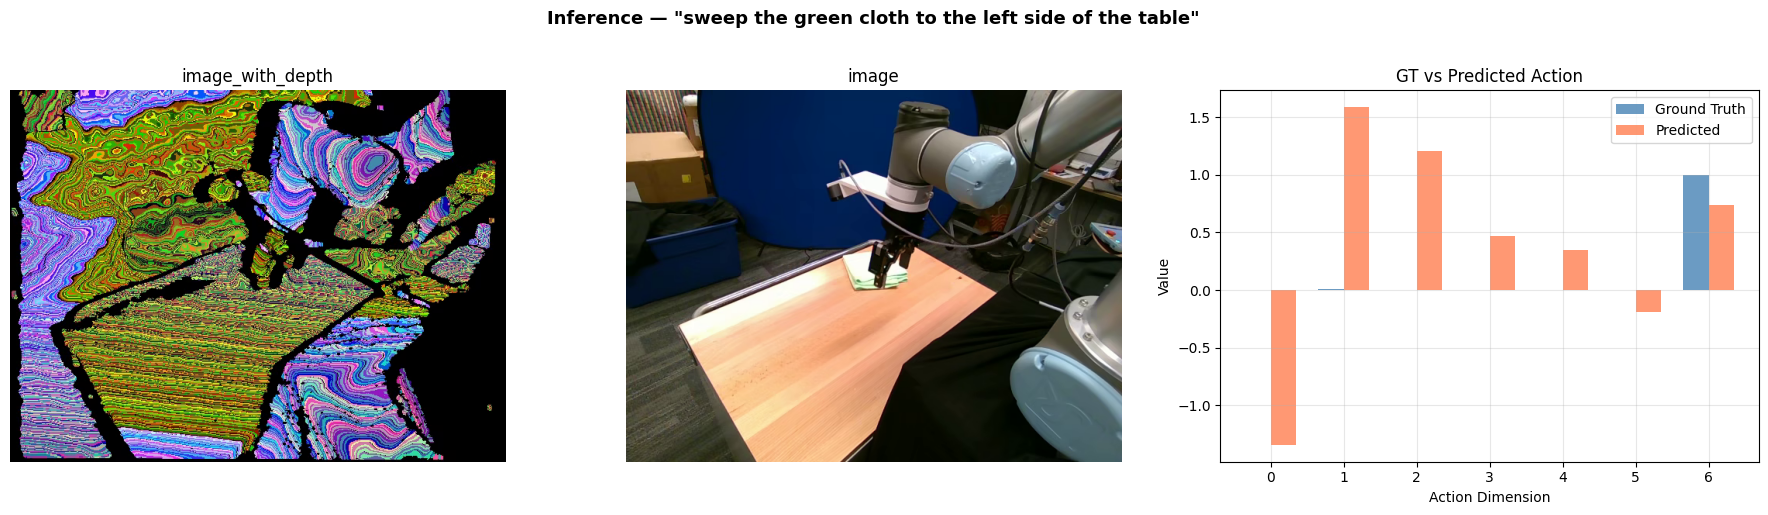


Sample 100 — Inference Results
Task: sweep the green cloth to the left side of the table
Action chunk shape: (1, 7)

Ground-truth action (this frame): [ 2.0000000e-02  0.0000000e+00 -0.0000000e+00  3.8095238e-04
  0.0000000e+00  0.0000000e+00  1.0000000e+00]
Predicted action (first step):     [-1.177937    1.4696157   0.67561626 -0.10389596 -0.09735815 -0.9383147
  0.75120175]

L2 error (first step): 2.239189


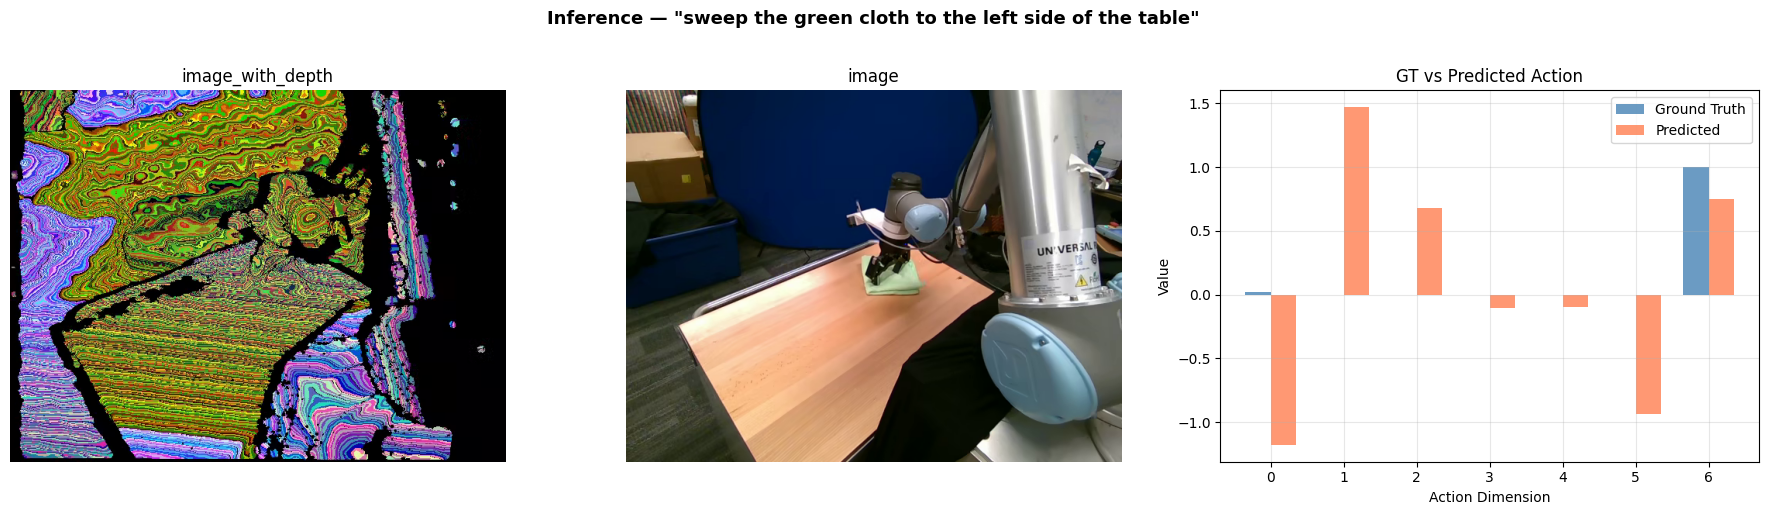


Sample 500 — Inference Results
Task: put the ranch bottle into the pot
Action chunk shape: (1, 7)

Ground-truth action (this frame): [ 0.00742857 -0.0084     -0.0028      0.03409524  0.06228571 -0.00647619
  0.        ]
Predicted action (first step):     [-1.2894558   1.667186    0.9549456   0.1933431  -0.18774492 -0.32468352
  0.74993384]

L2 error (first step): 2.481593


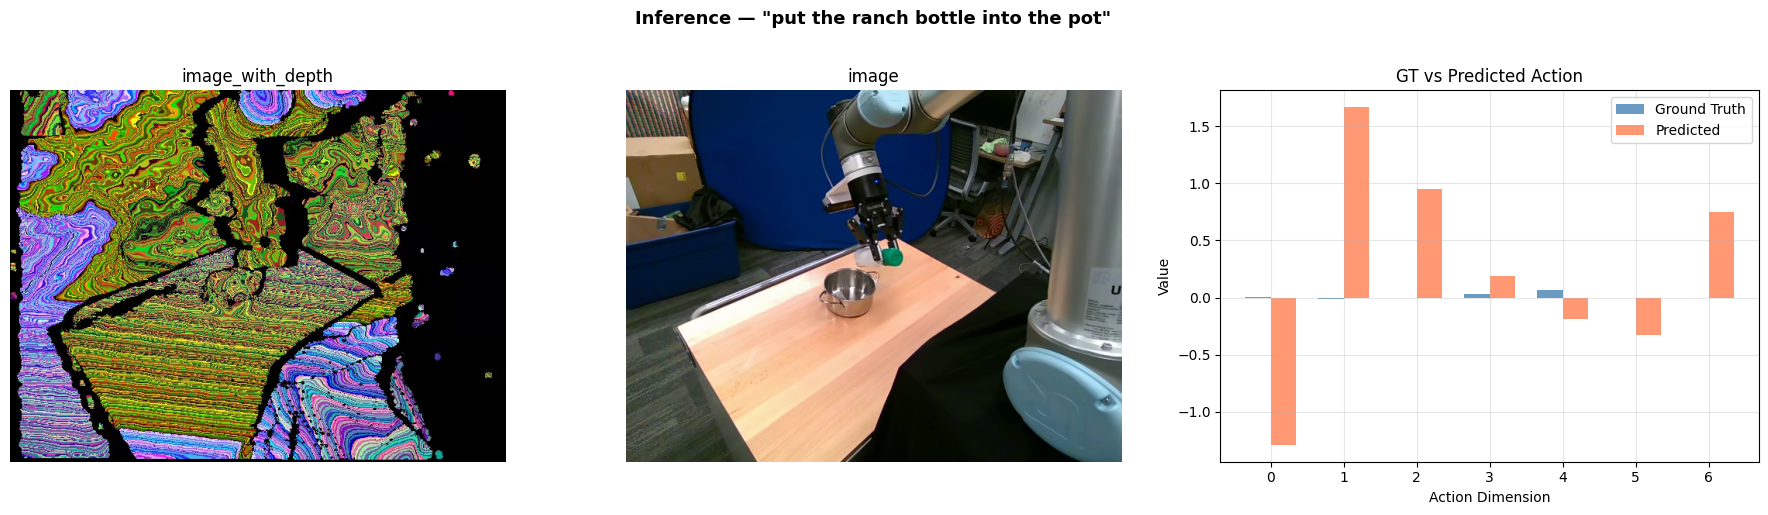

In [40]:
from transformers import AutoTokenizer

def run_inference_on_sample(policy, dataset, sample_idx=0, device='cuda'):
    """
    Run the policy on a single dataset sample and visualize predictions.
    """
    sample = dataset[sample_idx]
    
    # Build batch (add batch dimension)
    batch = {}
    for key, value in sample.items():
        if isinstance(value, torch.Tensor):
            batch[key] = value.unsqueeze(0).to(device)
        elif isinstance(value, str):
            batch[key] = [value]
        else:
            batch[key] = value
    
    # Tokenize the language instruction for SmolVLA
    tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolVLM2-500M-Video-Instruct")
    task_text = sample.get('task', sample.get('language_instruction', 'pick up the object'))
    tokenized = tokenizer(
        [task_text] if isinstance(task_text, str) else task_text,
        max_length=48,
        truncation=True,
        padding="max_length",
        return_tensors="pt",
    )
    batch["observation.language.tokens"] = tokenized["input_ids"].to(device)
    batch["observation.language.attention_mask"] = tokenized["attention_mask"].bool().to(device)
    
    # Run inference
    with torch.no_grad():
        action_chunk = policy.select_action(batch)
    
    predicted_actions = action_chunk.cpu().numpy()
    gt_action = sample['action'].numpy()
    
    print(f"\n{'='*60}")
    print(f"Sample {sample_idx} — Inference Results")
    print(f"{'='*60}")
    print(f"Task: {task_text}")
    print(f"Action chunk shape: {predicted_actions.shape}")
    print(f"\nGround-truth action (this frame): {gt_action}")
    print(f"Predicted action (first step):     {predicted_actions[0]}")
    print(f"\nL2 error (first step): {np.linalg.norm(predicted_actions[0] - gt_action):.6f}")
    
    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Camera views
    cam_keys = [k for k in sample.keys() if 'image' in k and isinstance(sample[k], torch.Tensor)]
    for i, cam_key in enumerate(cam_keys[:2]):
        img = sample[cam_key]
        if img.dim() == 3 and img.shape[0] in [1, 3]:
            img = img.permute(1, 2, 0)
        img_np = img.numpy()
        if img_np.max() <= 1.0:
            img_np = (img_np * 255).astype(np.uint8)
        axes[i].imshow(img_np)
        axes[i].set_title(cam_key.split('.')[-1], fontsize=12)
        axes[i].axis('off')
    
    # Action comparison
    x = np.arange(len(gt_action))
    width = 0.35
    axes[2].bar(x - width/2, gt_action, width, label='Ground Truth', color='steelblue', alpha=0.8)
    axes[2].bar(x + width/2, predicted_actions[0][:len(gt_action)], width, label='Predicted', color='coral', alpha=0.8)
    axes[2].set_xlabel('Action Dimension')
    axes[2].set_ylabel('Value')
    axes[2].set_title('GT vs Predicted Action', fontsize=12)
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    fig.suptitle(f'Inference — "{task_text}"', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    return predicted_actions

# Run inference on a few samples
for idx in [0, 100, 500]:
    run_inference_on_sample(policy, dataset, sample_idx=idx, device=str(device))


In [42]:
def evaluate_on_episodes(policy, dataset, episode_indices=[0, 1, 2], device='cuda'):
    """
    Compute average action prediction error across full episodes.
    """
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolVLM2-500M-Video-Instruct")
    
    results = []
    
    for ep_idx in episode_indices:
        errors = []
        found = False
        
        for i in range(len(dataset)):
            sample = dataset[i]
            curr_ep = sample.get('episode_index', -1)
            if isinstance(curr_ep, torch.Tensor):
                curr_ep = curr_ep.item()
            
            if curr_ep == ep_idx:
                found = True
                batch = {}
                for key, value in sample.items():
                    if isinstance(value, torch.Tensor):
                        batch[key] = value.unsqueeze(0).to(device)
                    elif isinstance(value, str):
                        batch[key] = [value]
                    else:
                        batch[key] = value
                
                # Tokenize language instruction
                task_text = sample.get('task', sample.get('language_instruction', 'pick up the object'))
                tokenized = tokenizer(
                    [task_text] if isinstance(task_text, str) else task_text,
                    max_length=48,
                    truncation=True,
                    padding="max_length",
                    return_tensors="pt",
                )
                batch["observation.language.tokens"] = tokenized["input_ids"].to(device)
                batch["observation.language.attention_mask"] = tokenized["attention_mask"].bool().to(device)
                
                with torch.no_grad():
                    pred = policy.select_action(batch)
                
                gt = sample['action'].numpy()
                pred_first = pred[0].cpu().numpy()[:len(gt)]
                error = np.linalg.norm(pred_first - gt)
                errors.append(error)
            elif found:
                break
        
        if errors:
            avg_err = np.mean(errors)
            results.append({'episode': ep_idx, 'mean_l2_error': avg_err, 'num_frames': len(errors)})
            print(f"Episode {ep_idx:4d} | Mean L2 Error: {avg_err:.6f} | Frames: {len(errors)}")
    
    return results

print("Evaluating on first 5 episodes...")
print("=" * 60)
eval_results = evaluate_on_episodes(policy, dataset, episode_indices=list(range(5)), device=str(device))


Evaluating on first 5 episodes...
Episode    0 | Mean L2 Error: 2.334380 | Frames: 71
Episode    1 | Mean L2 Error: 1.479013 | Frames: 76
Episode    2 | Mean L2 Error: 2.209949 | Frames: 81
Episode    3 | Mean L2 Error: 1.629023 | Frames: 80
Episode    4 | Mean L2 Error: 1.215473 | Frames: 123


---
## 8. Export the Model

Save and optionally push your fine-tuned model to the HuggingFace Hub.

In [43]:
# Save locally
export_dir = Path("smolvla_ur5_finetuned")
export_dir.mkdir(exist_ok=True)

policy.save_pretrained(str(export_dir))
print(f"✅ Policy saved to: {export_dir.absolute()}")
print(f"\nContents:")
for f in sorted(export_dir.rglob('*')):
    if f.is_file():
        print(f"  {f.name} ({f.stat().st_size / 1e6:.1f} MB)")

✅ Policy saved to: /home/grasplab/Desktop/VLA/berk/smolvla_ur5_finetuned

Contents:
  config.json (0.0 MB)
  model.safetensors (1197.8 MB)


In [ ]:
# (Optional) Push to HuggingFace Hub
# Uncomment and set your username below:

# HF_USERNAME = "your-username"
# REPO_NAME = "smolvla_berkeley_ur5"
# policy.push_to_hub(f"{HF_USERNAME}/{REPO_NAME}")
# print(f"✅ Pushed to: https://huggingface.co/{HF_USERNAME}/{REPO_NAME}")

---
## 9. Deployment Preview

To deploy this policy on your UR5 (simulated in Isaac Sim via ROS2), see the full deployment guide in **`book.md` Section 8**.

The deployment pipeline uses a ROS2 node (`smolvla_policy_node.py`) that:
1. Subscribes to `/joint_states` and camera image topics from Isaac Sim
2. Packs observations into the format expected by SmolVLA
3. Runs `policy.select_action(obs)` to get an action chunk
4. Publishes joint commands back to Isaac Sim's controller

```
Isaac Sim (UR5)  ──ROS2──▶  Policy Node  ──ROS2──▶  Isaac Sim (UR5)
  (observations)             (SmolVLA)              (joint commands)
```

Quick launch:
```bash
# Terminal 1: Isaac Sim with UR5 + ROS2 bridge
# Terminal 2:
source /opt/ros/humble/setup.bash
conda activate lerobot
python smolvla_policy_node.py \
    --ros-args \
    -p model_path:=smolvla_ur5_finetuned \
    -p language_instruction:="Pick up the blue cup and put it into the brown cup."
```

---

**🎉 Done!** You've successfully:
1. Explored the Berkeley UR5 dataset
2. Fine-tuned SmolVLA on UR5 manipulation tasks
3. Evaluated the trained policy
4. Exported the model for deployment

Next steps:
- Deploy on Isaac Sim (see `book.md` Section 8)
- Experiment with hyperparameters (learning rate, training steps)
- Collect your own UR5 data and fine-tune further